In [1]:
import numpy as np
import matplotlib.pyplot as plt
Data = np.array([[7.14, 7.37, 7.16], [7.575, 7.81, 7.535],
                [8.44, 8.595, 8.30],  [8.595, 8.81, 8.515],
                [8.656, 8.95, 9.015], [8.78, 8.94, 8.92],
                [8.81, 8.86, 8.45],  [7.84, 7.77, 7.92],
                [6.78, 6.89, 6.83]])
Mq = {'l-wire': 0.854, 'D-wire': 0.0019, 'W-rod': 0.165849,
      'l-rod': 0.1006, 'D-rod': 0.01325, 'RO': 0.0361, 'RI': 0.01184,
      'h-ring': 0.0108, 'W_ring': 0.07825}

In [2]:
k = []
for i in range(0, 9):
    k.append(np.mean(Data[i]))
D_avg = np.array(k)

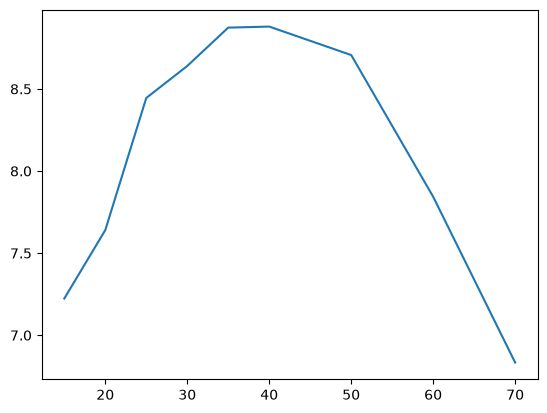

In [3]:
D = np.array([15, 20, 25, 30, 35, 40, 50, 60, 70])
plt.plot(D, D_avg)
D = D/100

In [4]:
Constant = ((1/12*(Mq['h-ring']**2)) + (1/4*(Mq['RI']**2+Mq['RO']**2))+1/4*(Mq['l-rod']**2))
MI = 1/12*Mq['W-rod']*Mq['l-rod']**2 + 1/4*Mq['W-rod']*Mq['RI']**2 + 2*Mq['W_ring']*Constant

In [5]:
print(MI)

0.0005996364937135999


In [6]:
T = D_avg/20

In [25]:
C = (1/T**2)*MI*4*(np.pi)**2
print(D_avg, C)

[7.22333333 7.64       8.445      8.64       8.87366667 8.88
 8.70666667 7.84333333 6.83333333] [0.18148155 0.16222623 0.13277261 0.12684703 0.12025456 0.12008309
 0.12491194 0.15392403 0.20278815]


In [8]:
k = 1/(2*D) + 1/(2*(Mq['l-wire']-D))
mrig = C*(1/(np.pi*(Mq['D-wire']/2)**4)*(1/k))

In [9]:
print(mrig)

[1.75397832e+10 1.94203316e+10 1.83490361e+10 1.92947497e+10
 1.94145789e+10 1.99583911e+10 2.02350856e+10 2.14693669e+10
 2.00073313e+10]


[8.08712121 6.52905199 5.65562914 5.13838748 4.84126984 4.70264317
 4.82485876 5.60367454 7.92207792]
0.018084437205342304


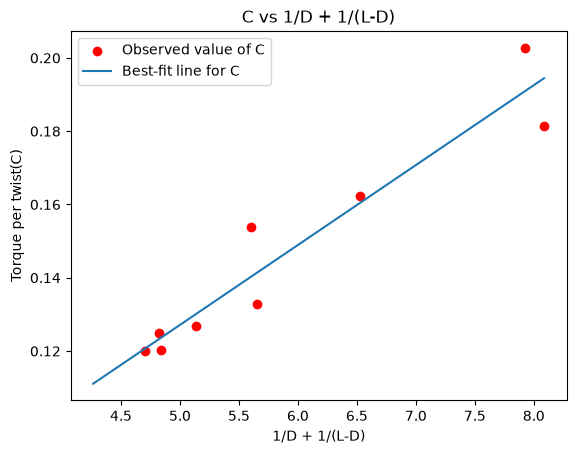

In [37]:
k2 = 1/(D) + 1/((Mq['l-wire']-D))
print(k2)
plt.scatter(k2, C, color='red', label='Observed value of C')
m, c = np.polyfit(k2, C, 1)
p = np.linspace(4.26431718, 8.0871212121, 200)
print(c)
plt.plot(p, m*p + c, label='Best-fit line for C')
plt.xlabel('1/D + 1/(L-D)')
plt.ylabel('Torque per twist(C)')
plt.title('C vs 1/D + 1/(L-D)')
plt.legend()

In [27]:
print(np.mean(mrig))
print(np.mean(C))

19520961588.593124
0.14725435347334218


In [12]:
print(m*2/(np.pi*(Mq['D-wire']/2)**4))

17046058372.523739


In [13]:
print(max(mrig), min(mrig))

21469366868.572544 17539783168.220387


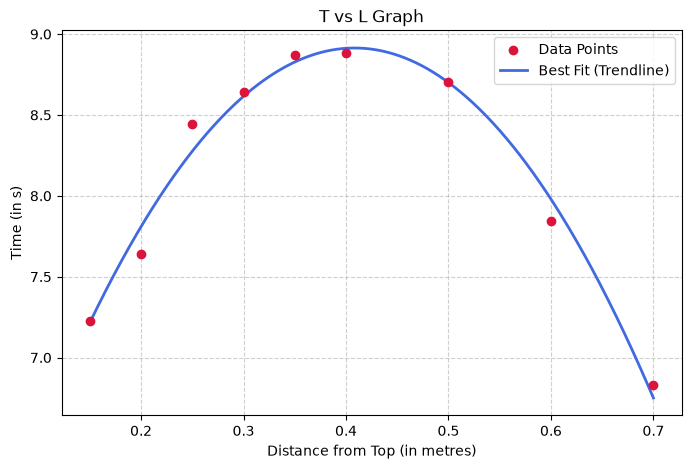

In [39]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Create dummy jagged/noisy U-shaped data
# np.random.seed(42)
x_data = D
# A basic quadratic function (U-shape) with added random noise
y_data = D_avg

# 2. Calculate the best-fit curve (2nd-degree polynomial for a U-shape)
coefficients = np.polyfit(x_data, y_data, deg=2)  # deg=2 creates the parabola (ax² + bx + c)
polynomial = np.poly1d(coefficients)

# 3. Generate a smooth set of X values for the curve
# Instead of 7 points, we generate 500 points between the min and max X
x_smooth = np.linspace(x_data.min(), x_data.max(), 500)
y_smooth = polynomial(x_smooth)

# 4. Plotting
plt.figure(figsize=(8, 5))

# Plot the individual data points (some will sit on or away from the line)
plt.scatter(x_data, y_data, color='crimson', label='Data Points', zorder=5)

# Plot the perfectly smooth best-fit curve
plt.plot(x_smooth, y_smooth, color='royalblue', linewidth=2, label='Best Fit (Trendline)')

# Styling the chart
plt.title('T vs L Graph')
plt.xlabel('Distance from Top (in metres)')
plt.ylabel('Time (in s)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()

plt.show()


In [20]:
'''
Error Analysis Least fit squared and Absolute Error
'''
SSE = 0
for i in range(0, 9):
    y1 = coefficients[0]*D[i]**2 + coefficients[1]*D[i] + coefficients[2]
    y2 = D_avg
    SSE += (y1 - y2[i])**2
    print(y1, y2[i], (y1 - y2[i])**2)

print("final SSE", SSE)
print("final Standard error", np.sqrt(SSE/6))

7.215384445559457 7.223333333333334 6.318481684168295e-05
7.809204671907231 7.640000000000001 0.028630220995233647
8.275800836260245 8.445 0.028628357010232412
8.6151729386185 8.64 0.0006163829768408147
8.827320978981994 8.873666666666667 0.002147922766965195
8.912244957350728 8.88 0.001039737274550208
8.700420728103918 8.706666666666667 3.901174852963669e-05
7.979700250878068 7.843333333333334 0.018595936200652332
6.750083525673178 6.833333333333333 0.00693053047545282
final SSE 0.08669128426529875
final Standard error 0.1202021105370026


In [16]:
abs_err = 0
for i in range(0,9):
    y1 = coefficients[0]*D[i]**2 + coefficients[1]*D[i] + coefficients[2]
    y2 = D_avg
    abs_err += abs(y1 - y2[i])
    print(abs_err)

print("Final Absolute Error ", abs_err/9)

0.007948887773876478
0.17715355968110735
0.3463527234208623
0.37117978480236324
0.41752547248703564
0.4497704298377627
0.45601636840051185
0.592383285945246
0.6756330936054011
Final Absolute Error  0.07507034373393345


In [19]:
L_mean = np.mean(D)
delta_m = np.sqrt((SSE)/(6*(L_mean - D)**2))
print(delta_m)

[0.5151519  0.65564788 0.90151583 1.44242533 3.60606332 7.21212663
 1.0303038  0.55477897 0.37958561]


In [28]:
print(coefficients)

[-25.4448124   20.78208887   4.67057939]


In [30]:
C_mean = np.mean(C)
z = 0
for i in range(0, 9):
    z += abs(C[i]-C_mean)
print(z)

0.2228050861832468


In [31]:
n_mean = np.mean(mrig)
z = 0
for i in range(0, 9):
    z += abs(mrig[i]-n_mean)
print(z)

7172656909.566444


In [32]:
C_std = np.std(C)
print(C_std/(np.sqrt(9)))

0.009373441975611747


In [33]:
n_std = np.std(mrig)
print(n_std/(np.sqrt(9)))

353208382.1359088
